In [5]:
#Importer les bbliotheque necessaire
#Pytorch et pyplot de matplotlib 

import torch
import torchvision
import matplotlib.pyplot as pyplot

print("Pytorch :", torch.__version__)
print("torchvision : ", torchvision.__version__)

Pytorch : 2.14.1+cpu
torchvision :  0.29.1+cpu


Crée une transformation qui convertit chaque image en tenseur PyTorch. Les pixels passent de valeurs entières entre 0 et 255 à des nombres décimaux entre 0 et 1. Le modèle apprend généralement plus facilement avec ces valeurs normalisées.

In [ ]:
#Crée une transformation qui convertit chaque image en tenseur PyTorch
#Cette transformation sera appliquée à chaque image du dataset lors du chargement
#Elle permet de convertir les images en tenseurs PyTorch, ce qui est nécessaire pour les utiliser avec les modèles PyTorch
transform = torchvision.transforms.ToTensor()

Charge les images qui serviront à entraîner le modèle.

root="data" : indique où enregistrer les fichiers du jeu de données.
train=True : demande la partie entraînement.
download=True : télécharge MNIST si les fichiers ne sont pas déjà présents.
transform=transform : applique la conversion en tenseurs à chaque image.

In [ ]:

#Télécharge et charge le dataset MNIST pour l'entraînement
#Le paramètre 'root' spécifie le répertoire où les données seront stockées
#Le paramètre 'train' indique que nous voulons le jeu de données d'entraînement
#Le paramètre 'download' permet de télécharger les données si elles ne sont pas déjà présentes
#Le paramètre 'transform' applique la transformation définie précédemment à chaque image
train_data = torchvision.datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

100.0%
100.0%
100.0%
100.0%


Charge la partie test, qui servira plus tard à vérifier si le modèle reconnaît aussi des images qu’il n’a pas utilisées pour apprendre. train=False sélectionne ces données.

In [9]:
#Télécharge et charge le dataset MNIST pour le test
#Le paramètre 'root' spécifie le répertoire où les données seront stockées
#Le paramètre 'train' indique que nous voulons le jeu de données de test
#Le paramètre 'download' permet de télécharger les données si elles ne sont pas déjà présentes
#Le paramètre 'transform' applique la transformation définie précédemment à chaque image
test_data = torchvision.datasets.MNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)

len(...) compte le nombre d’images dans chaque jeu de données. Le f devant le texte permet d’insérer le résultat directement dans la chaîne avec {...}.

In [10]:
print(f"Images d'entraînement : {len(train_data)}")
print(f"Images de test : {len(test_data)}")



Images d'entraînement : 60000
Images de test : 10000


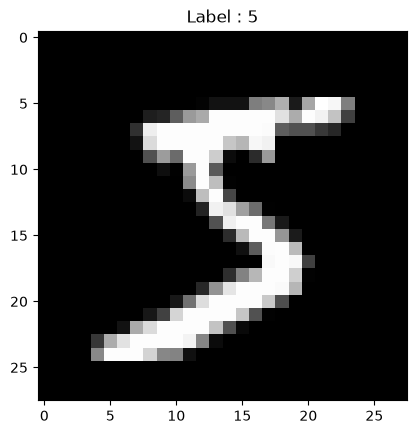

In [31]:
#Afficher un exemple d'image d'entraînement
import matplotlib.pyplot as plt
image, label = train_data[0]
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Label : {label}")
plt.show()



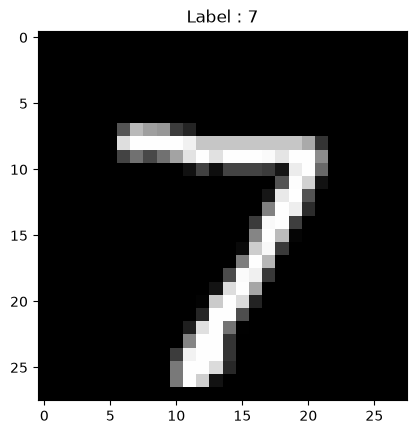

In [41]:
#Afficher un exemple d'image de test
image, label = test_data[0]
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Label : {label}")
plt.show()

Récupère le premier exemple d’entraînement. Chaque exemple contient deux éléments :

image : l’image du chiffre, sous forme de tenseur ;
label : le chiffre attendu, un nombre entre 0 et 9.

In [42]:
image, label = train_data[0]

Affiche la forme du tenseur et l’étiquette. La forme devrait ressembler à torch.Size([1, 28, 28]) : 1 canal (niveaux de gris), 28 pixels de haut et 28 pixels de large.

In [37]:
print(f"Forme de l'image : {image.shape}")
print(f"Chiffre attendu : {label}")

Forme de l'image : torch.Size([1, 28, 28])
Chiffre attendu : 5


Affiche l’image :

squeeze() retire la dimension du canal, qui vaut 1, pour que l’affichage reçoive une matrice de 28 × 28 pixels ;
cmap="gray" choisit une palette en niveaux de gris.

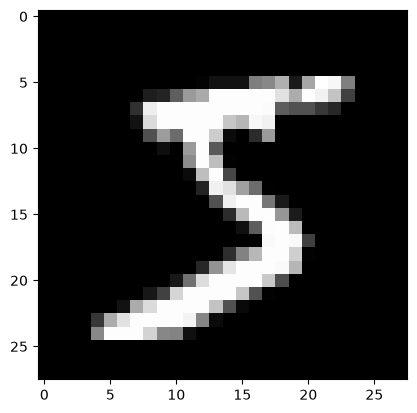

In [19]:
pyplot.imshow(image.squeeze(), cmap="gray")

Ajoute le chiffre attendu comme titre, masque les axes, puis affiche le graphique.

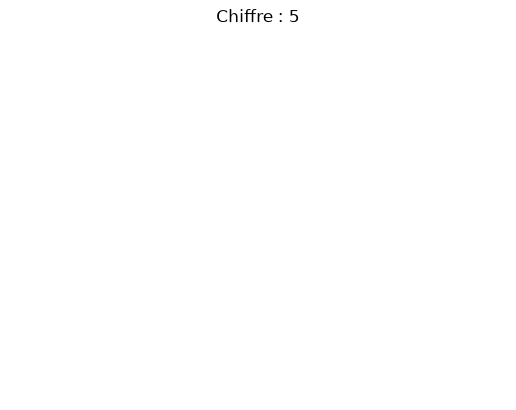

In [20]:
pyplot.title(f"Chiffre : {label}")
pyplot.axis("off")
pyplot.show()

In [ ]:
# importe l outil PyTorch qui organise un jeu de donnees en lots.
from torch.utils.data import DataLoader

batch_size = 64

train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False
)